In [1]:
from models.unet import SiameseUNet
from lightning import Trainer
from lightning.pytorch.loggers import TensorBoardLogger
from data.data import SpagDataModule
from lightning.pytorch.callbacks import ModelCheckpoint

data_module=SpagDataModule(
    root_folder="/home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1",
    subfolders=["01","02","02"],
    batch_size=1,
    max_length_of_training_samples=1,
    max_length_of_validation_samples=1,
    max_length_of_testing_samples=100,
    expected_min=0,
    expected_max=255
)




Found min and max values of images:  0 221
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
Found min and max values of images:  0 155
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
Found min and max values of images:  0 182
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
######## Successfully loaded datasets ########
Root folder: /home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1
Train dataset length: 1
Val dataset length: 1
Test dataset length: 92
###############################################


In [23]:
model= SiameseUNet.load_from_checkpoint(
    # checkpoint_path="/mnt/helix/FeatureNet_seg/training_logs/SiameseUNet/32feat_True_pos/DIC-C2DH-HeLa/version_0/checkpoints/best_model_epoch=34.ckpt")
    checkpoint_path='./training_logs/SiameseUNet_aug/SinePositionalEncoding/Fluo-N2DH-GOWT1/version_1/checkpoints/last.ckpt')
model.eval()

SiameseUNet(
  (loss_fn_seg): BCEWithLogitsLoss()
  (model): SiameseUNetBase(
    (down): UnetDown(
      (encoder): ModuleList(
        (0): UNetBlock(
          (block): Sequential(
            (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (3): ReLU(inplace=True)
          )
        )
        (1): UNetBlock(
          (block): Sequential(
            (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (3): ReLU(inplace=True)
          )
        )
        (2): UNetBlock(
          (block): Sequential(
            (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1

In [24]:
preds=model.predict_from_dataloader(data_module.test_dataloader(), thresh=0.5, disable_tqdm=False, keep_pseudo_probs=True)

Predicting: 100%|██████████| 92/92 [00:16<00:00,  5.49it/s]


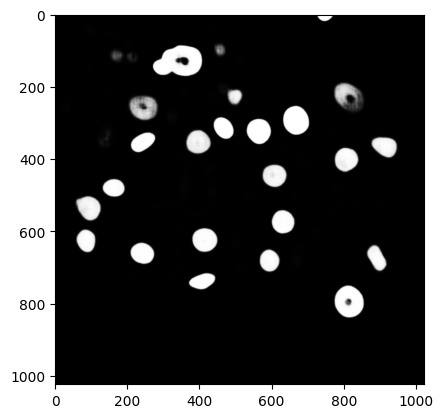

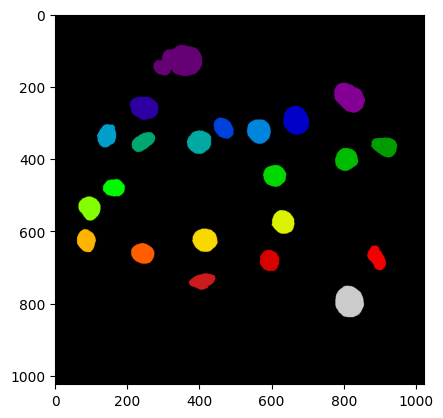

In [25]:
import matplotlib.pyplot as plt
from torch import sigmoid
plt.figure()
plt.imshow(preds[0][0].detach().cpu().numpy().squeeze(), cmap='gray')

gt=data_module.test_ds[0][1].detach().cpu().numpy().squeeze()

plt.figure()
plt.imshow(gt, cmap='nipy_spectral')

Running t-SNE on 5000 pixels...


/tmp/ipykernel_49947/850742483.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_labels))


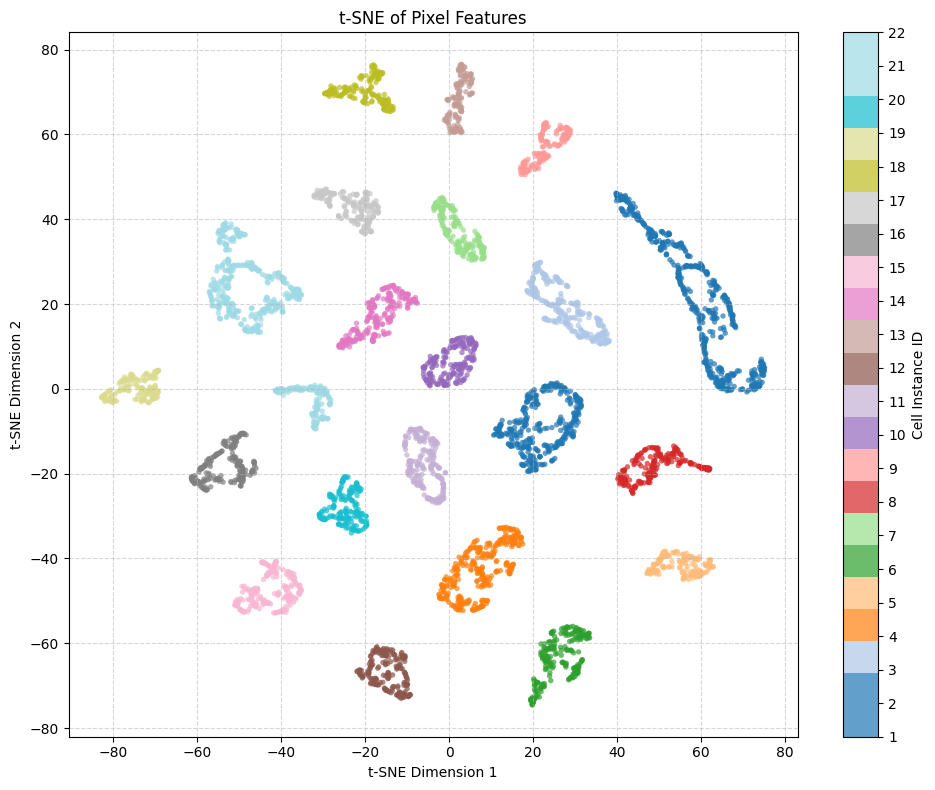

In [26]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def visualize_features_tsne(features, instance_mask, max_samples=5000, include_background=False):
    """
    Applies t-SNE to a feature map to visualize if pixels from the same 
    cell cluster together.
    
    Args:foreground
        features: Tensor of shape (C, H, W)
        instance_mask: Tensor of shape (H, W) with ground truth integer labels
        max_samples: Maximum number of pixels to process (t-SNE is slow for N > 10000)
        include_background: Whether to include background pixels (ID=0) in the plot
    """

    C, H, W = features.shape
    
    # 2. Flatten spatial dimensions
    # features_flat: (H*W, C)
    # mask_flat: (H*W,)
    features_flat = features.reshape(C, -1).T
    mask_flat = instance_mask.flatten()
    
    # 3. Filter pixels (remove background if requested)
    if include_background:
        valid_indices = np.arange(len(mask_flat))
    else:
        valid_indices = np.where(mask_flat > 0)[0]
        
    if len(valid_indices) == 0:
        print("No foreground pixels found to plot.")
        return
        
    # 4. Randomly subsample to keep t-SNE fast
    if len(valid_indices) > max_samples:
        selected_indices = np.random.choice(valid_indices, size=max_samples, replace=False)
    else:
        selected_indices = valid_indices
        
    sampled_features = features_flat[selected_indices]
    sampled_labels = mask_flat[selected_indices]
    
    # 5. Run t-SNE
    print(f"Running t-SNE on {len(sampled_features)} pixels...")
    # init='pca' is generally more stable than random initialization
    tsne = TSNE(n_components=2, init='pca', learning_rate='auto', random_state=42)
    embeddings = tsne.fit_transform(sampled_features)
    
    # 6. Plotting
    plt.figure(figsize=(10, 8))
    
    # Use a distinct colormap for instances
    unique_labels = np.unique(sampled_labels)
    # 'tab20' provides 20 distinct colors, which loops if you have >20 cells
    cmap = plt.cm.get_cmap('tab20', len(unique_labels)) 
    
    # Scatter plot
    scatter = plt.scatter(
        embeddings[:, 0], 
        embeddings[:, 1], 
        c=sampled_labels, 
        cmap=cmap, 
        alpha=0.7, 
        s=15, # marker size
        edgecolors='none'
    )
    
    # Add a colorbar and labels
    cbar = plt.colorbar(scatter, ticks=unique_labels)
    cbar.set_label('Cell Instance ID')
    
    plt.title("t-SNE of Pixel Features")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


features=preds[0][1].detach().cpu().numpy().squeeze()
instance_mask=gt

visualize_features_tsne(features, instance_mask, max_samples=5000, include_background=False)


In [ ]:
from tracking_functions import cluster_features_to_instances

model=None

instance_masks=[]
for i in range(0, len(preds)):
    foreground_mask = (preds[i][0].detach().cpu().numpy().squeeze() > 0.5).astype(np.uint8)
    print(foreground_mask.min(), foreground_mask.max())
    instance_mask = cluster_features_to_instances(preds[i][1], foreground_mask, method='hdbscan', margin=1.5, min_cell_size=1000)
    instance_masks.append(instance_mask)


0 1
Clustering 70790 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 70204 foreground pixels using HDBSCAN...
Detected 21 instances.
0 1
Clustering 70650 foreground pixels using HDBSCAN...
Detected 21 instances.
0 1
Clustering 70223 foreground pixels using HDBSCAN...
Detected 21 instances.
0 1
Clustering 72757 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 73726 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 73513 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 71464 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 70898 foreground pixels using HDBSCAN...
Detected 21 instances.
0 1
Clustering 71710 foreground pixels using HDBSCAN...
Detected 21 instances.
0 1
Clustering 73571 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 72435 foreground pixels using HDBSCAN...
Detected 21 instances.
0 1
Clustering 70800 foreground pixels using HDBSCAN

In [ ]:
import napari
import tifffile
gt=[data_module.test_ds[i][1].detach().cpu().numpy().squeeze() for i in range(len(data_module.test_ds))]
viewer=napari.Viewer()
viewer.add_image(tifffile.imread("/home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1/02/video.tiff"), name="raw")
viewer.add_labels(np.array(gt).astype(np.uint8), name="GT")
viewer.add_labels(np.array(instance_masks).astype(np.uint8).squeeze(), name="Predicted Instances")

AttributeError: 'list' object has no attribute 'squeeze'

In [33]:
from tracking_functions import instance_mask_to_features    
instance_features=np.empty((0, preds[0][1].shape[-3]), dtype=np.float32)
frames=[]
inst_locs=np.empty((0, 2), dtype=np.float32)
for i in range(len(preds)):
    inst_features, inst_loc = instance_mask_to_features(instance_masks[i].squeeze(), preds[i][1].squeeze())
    instance_features= np.concatenate((instance_features, inst_features), axis=0)
    frames= np.concatenate((frames, np.ones(inst_features.shape[0])*i), axis=0)
    inst_locs= np.concatenate((inst_locs, inst_loc), axis=0)
print(instance_features.shape, frames.shape, inst_locs.shape)

(2195, 8) (2195,) (2195, 2)


Text(0.5, 1.0, 't-SNE of Instance Features Colored by Frame Index')

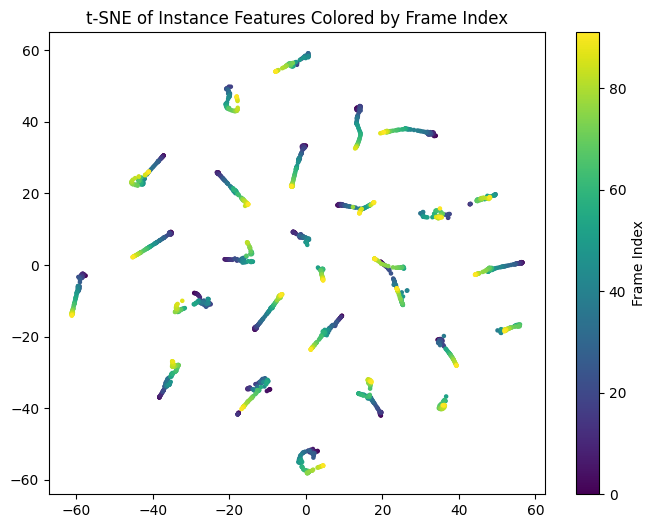

In [34]:
# visualize the instance features in 2D using Tsne
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42)
instance_features_2d = tsne.fit_transform(instance_features)   
from matplotlib import pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(instance_features_2d[:, 0], instance_features_2d[:, 1], c=frames, cmap='viridis', s=5)
plt.colorbar(label='Frame Index')
plt.title('t-SNE of Instance Features Colored by Frame Index')